In [ ]:

# SMART FAKE NEWS DETECTION SYSTEM
# Project Environment Setup

import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

print("===================================")
print(" SMART FAKE NEWS DETECTION SYSTEM")
print("===================================")

print("Python Version:", sys.version)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("Matplotlib Version:", matplotlib.__version__)
print("Scikit-learn Version:", sklearn.__version__)

print("\nEnvironment setup completed successfully!")


 SMART FAKE NEWS DETECTION SYSTEM
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy Version: 2.4.6
Pandas Version: 2.2.3
Matplotlib Version: 3.10.0
Scikit-learn Version: 1.6.1

Environment setup completed successfully!


In [ ]:


from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [ ]:
import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

folders = [
    "data",
    "notebooks",
    "src",
    "app",
    "models",
    "outputs/visualizations",
    "outputs/evaluation_results",
    "screenshots"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")
print("Project location:", project_path)

Project folders created successfully!
Project location: /content/drive/MyDrive/Smart_Fake_News_Detection


In [ ]:
import os
import shutil
import urllib.request
import zipfile
from pathlib import Path

# Google Drive project data folder
data_path = Path(
    "/content/drive/MyDrive/Smart_Fake_News_Detection/data"
)

data_path.mkdir(parents=True, exist_ok=True)

# Official University of Victoria dataset
url = (
    "https://onlineacademiccommunity.uvic.ca/isot/"
    "wp-content/uploads/sites/7295/2023/03/News-_dataset.zip"
)

zip_path = "/content/ISOT_Fake_News_Dataset.zip"

print("Downloading dataset... Please wait.")
urllib.request.urlretrieve(url, zip_path)
print("Download completed!")

# Extract the ZIP file
print("Extracting dataset...")
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_path)

# Find and place the two CSV files directly inside data
for root, dirs, files in os.walk(data_path):
    for filename in files:
        if filename.lower() in ["fake.csv", "true.csv"]:
            source = Path(root) / filename
            destination = data_path / filename
            if source.resolve() != destination.resolve():
                shutil.copy2(source, destination)

# Verify the files
print("\nDATASET FILE CHECK")
for filename in ["Fake.csv", "True.csv"]:
    file_path = data_path / filename
    if file_path.exists():
        print("SUCCESS:", filename, "is available!")
        print("File size:", round(file_path.stat().st_size / (1024 * 1024), 2), "MB")
    else:
        print("NOT FOUND:", filename)

print("\nDataset download and extraction step finished!")

Download completed!
Extracting dataset...

DATASET FILE CHECK
SUCCESS: Fake.csv is available!
File size: 59.88 MB
SUCCESS: True.csv is available!
File size: 51.1 MB

Dataset download and extraction step finished!


In [ ]:
import pandas as pd
import os

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

fake_news = pd.read_csv(os.path.join(data_path, "Fake.csv"))
real_news = pd.read_csv(os.path.join(data_path, "True.csv"))

# Add labels
fake_news["label"] = 0
real_news["label"] = 1

# Combine both datasets
news_data = pd.concat(
    [fake_news, real_news],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("\nTotal number of articles:", len(news_data))

print("\nDataset columns:")
print(news_data.columns.tolist())

print("\nFirst five articles:")
display(news_data.head())

print("\nNumber of fake and real articles:")
print(news_data["label"].value_counts())

print("\nMissing values:")
print(news_data.isnull().sum())

print("\nDuplicate rows:", news_data.duplicated().sum())

# Save combined dataset
news_data.to_csv(
    os.path.join(data_path, "combined_news.csv"),
    index=False
)

print("\nCombined dataset saved successfully!")

Dataset loaded successfully!

Total number of articles: 44898

Dataset columns:
['title', 'text', 'subject', 'date', 'label']

First five articles:


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0



Number of fake and real articles:
label
0    23481
1    21417
Name: count, dtype: int64

Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate rows: 209

Combined dataset saved successfully!


In [ ]:
import pandas as pd
import re
import os

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

news_data = pd.read_csv(
    os.path.join(data_path, "combined_news.csv")
)

# Remove duplicate rows
news_data = news_data.drop_duplicates(
    subset=["title", "text", "label"]
)

# Remove rows with missing article information
news_data = news_data.dropna(
    subset=["title", "text", "label"]
)

# Combine headline and article text
news_data["content"] = (
    news_data["title"].astype(str) + " " +
    news_data["text"].astype(str)
)

# Clean article text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

news_data["content"] = news_data["content"].apply(clean_text)

# Remove empty articles
news_data = news_data[
    news_data["content"].str.len() > 0
]

# Save cleaned dataset
cleaned_path = os.path.join(data_path, "cleaned_news.csv")
news_data.to_csv(cleaned_path, index=False)

print("Data cleaning completed successfully!")
print("\nTotal cleaned articles:", len(news_data))
print("\nFake and real article counts:")
print(news_data["label"].value_counts())

print("\nMissing values:")
print(news_data[["content", "label"]].isnull().sum())

print("\nSample cleaned article:")
print(news_data["content"].iloc[0][:500])

print("\nCleaned dataset saved successfully!")

Data cleaning completed successfully!

Total cleaned articles: 39100

Fake and real article counts:
label
1    21197
0    17903
Name: count, dtype: int64

Missing values:
content    0
label      0
dtype: int64

Sample cleaned article:
donald trump sends out embarrassing new year s eve message this is disturbing donald trump just couldn t wish all americans a happy new year and leave it at that instead he had to give a shout out to his enemies haters and the very dishonest fake news media the former reality show star had just one job to do and he couldn t do it as our country rapidly grows stronger and smarter i want to wish all of my friends supporters enemies haters and even the very dishonest fake news media a happy and hea

Cleaned dataset saved successfully!


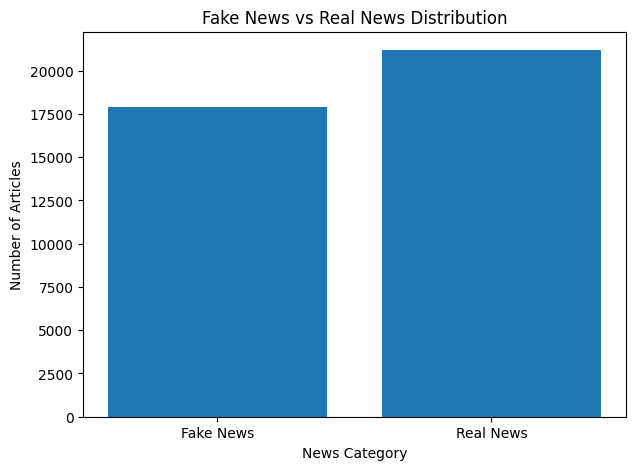

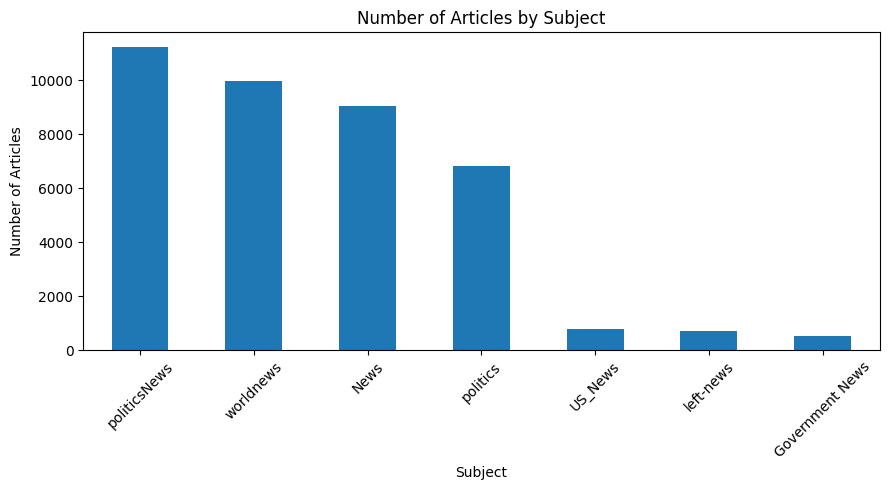

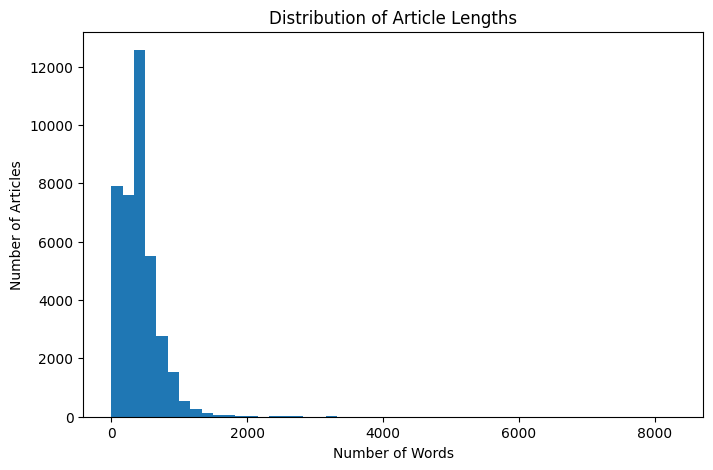

EDA completed successfully!

Article length statistics:
count    39100.000000
mean       415.524271
std        319.109498
min          3.000000
25%        222.000000
50%        383.000000
75%        528.000000
max       8295.000000
Name: article_length, dtype: float64

Analysis data saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

news_data = pd.read_csv(
    os.path.join(data_path, "cleaned_news.csv")
)

# Graph 1: Fake and real news distribution
news_counts = news_data["label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Fake News", "Real News"],
    [news_counts.get(0, 0), news_counts.get(1, 0)]
)
plt.title("Fake News vs Real News Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.show()

# Graph 2: Articles by subject
subject_counts = news_data["subject"].value_counts()

plt.figure(figsize=(9, 5))
subject_counts.plot(kind="bar")
plt.title("Number of Articles by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Graph 3: Article length distribution
news_data["article_length"] = news_data["content"].apply(
    lambda text: len(str(text).split())
)

plt.figure(figsize=(8, 5))
plt.hist(news_data["article_length"], bins=50)
plt.title("Distribution of Article Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.show()

print("EDA completed successfully!")
print("\nArticle length statistics:")
print(news_data["article_length"].describe())

# Save the updated analysis data
news_data.to_csv(
    os.path.join(data_path, "cleaned_news.csv"),
    index=False
)

print("\nAnalysis data saved successfully!")

In [ ]:
import pandas as pd
import os
import re

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

news_data = pd.read_csv(
    os.path.join(data_path, "combined_news.csv")
)

print("Original number of articles:", len(news_data))

# Remove rows with missing article text
news_data = news_data.dropna(subset=["text"])

# Remove duplicate articles
news_data = news_data.drop_duplicates(subset=["text"])

# Combine headline and article text
news_data["title"] = news_data["title"].fillna("")

news_data["content"] = (
    news_data["title"] + " " + news_data["text"]
)

# Clean the article text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

news_data["content"] = news_data["content"].apply(clean_text)

# Remove empty articles
news_data = news_data[news_data["content"] != ""]

# Keep only the required columns
cleaned_data = news_data[["content", "label"]].copy()

# Save cleaned dataset
cleaned_data.to_csv(
    os.path.join(data_path, "cleaned_news.csv"),
    index=False
)

print("\nData cleaning completed successfully!")
print("Total articles after cleaning:", len(cleaned_data))

print("\nFake and real news count:")
print(cleaned_data["label"].value_counts())

print("\nFirst five cleaned articles:")
display(cleaned_data.head())

print("\nCleaned dataset saved successfully!")

Original number of articles: 44898

Data cleaning completed successfully!
Total articles after cleaning: 38641

Fake and real news count:
label
1    21191
0    17450
Name: count, dtype: int64

First five cleaned articles:


,content,label
0,donald trump sends out embarrassing new year s...,0
1,drunk bragging trump staffer started russian c...,0
2,sheriff david clarke becomes an internet joke ...,0
3,trump is so obsessed he even has obama s name ...,0
4,pope francis just called out donald trump duri...,0



Cleaned dataset saved successfully!


In [ ]:
import pandas as pd
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

cleaned_data = pd.read_csv(
    os.path.join(data_path, "cleaned_news.csv")
)

X = cleaned_data["content"]
y = cleaned_data["label"]

# Divide data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Data preparation completed successfully!")

print("\nTraining articles:", X_train_tfidf.shape[0])
print("Testing articles:", X_test_tfidf.shape[0])

print("\nTraining features:", X_train_tfidf.shape[1])
print("Testing features:", X_test_tfidf.shape[1])

print("\nTF-IDF conversion completed successfully!")

Data preparation completed successfully!

Training articles: 30912
Testing articles: 7729

Training features: 5000
Testing features: 5000

TF-IDF conversion completed successfully!


Logistic Regression Model Trained Successfully!

Model Accuracy: 98.43 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.97      0.98      3490
   Real News       0.98      0.99      0.99      4239

    accuracy                           0.98      7729
   macro avg       0.99      0.98      0.98      7729
weighted avg       0.98      0.98      0.98      7729



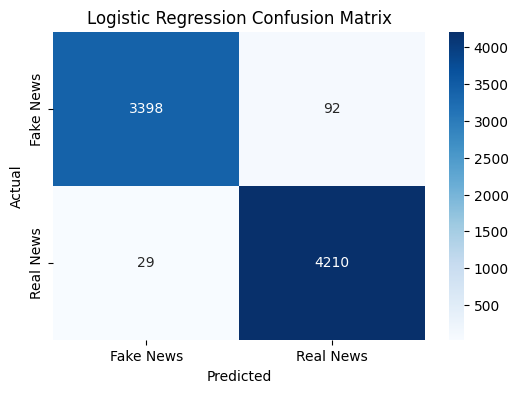

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create and train the model
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_tfidf, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test_tfidf)

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Model Trained Successfully!")

print("\nModel Accuracy:", round(logistic_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=["Fake News", "Real News"]
))

# Display confusion matrix
cm = confusion_matrix(y_test, logistic_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

Multinomial Naive Bayes Model Trained Successfully!

Model Accuracy: 93.04 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.92      0.92      0.92      3490
   Real News       0.94      0.94      0.94      4239

    accuracy                           0.93      7729
   macro avg       0.93      0.93      0.93      7729
weighted avg       0.93      0.93      0.93      7729



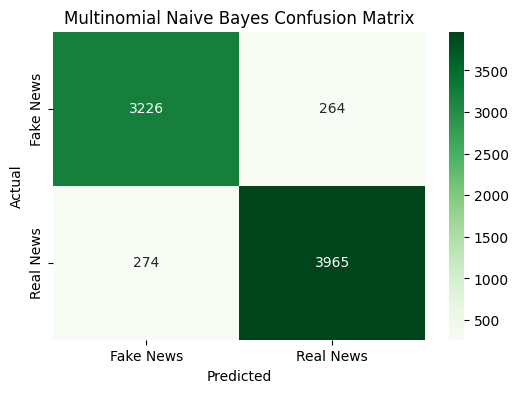

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create and train the model
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test_tfidf)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Multinomial Naive Bayes Model Trained Successfully!")

print("\nModel Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Fake News", "Real News"]
))

# Display confusion matrix
cm = confusion_matrix(y_test, nb_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Multinomial Naive Bayes Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
import pandas as pd

# Calculate performance of both models
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, nb_predictions)
    ],
    "Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, nb_predictions)
    ],
    "Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, nb_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, nb_predictions)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

# Select the model with the higher F1 score
best_model_name = results.loc[
    results["F1 Score"].idxmax(), "Model"
]

print("\nSelected Model:", best_model_name)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9843,0.9786,0.9932,0.9858
1,Multinomial Naive Bayes,0.9304,0.9376,0.9354,0.9365



Selected Model: Logistic Regression


In [ ]:
import os
import joblib
import pandas as pd

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

models_path = os.path.join(project_path, "models")
outputs_path = os.path.join(
    project_path, "outputs", "evaluation_results"
)

os.makedirs(models_path, exist_ok=True)
os.makedirs(outputs_path, exist_ok=True)

# Save the selected model
joblib.dump(
    logistic_model,
    os.path.join(models_path, "model.joblib")
)

# Save the fitted TF-IDF vectorizer
joblib.dump(
    tfidf,
    os.path.join(models_path, "tfidf_vectorizer.joblib")
)

# Save model comparison results
results.to_csv(
    os.path.join(outputs_path, "model_comparison.csv"),
    index=False
)

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")
print("Comparison results saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!
Comparison results saved successfully!


In [ ]:
import os
import joblib
import pandas as pd

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

models_path = os.path.join(project_path, "models")
outputs_path = os.path.join(
    project_path, "outputs", "evaluation_results"
)

os.makedirs(models_path, exist_ok=True)
os.makedirs(outputs_path, exist_ok=True)

# Save the selected model
joblib.dump(
    logistic_model,
    os.path.join(models_path, "model.joblib")
)

# Save the fitted TF-IDF vectorizer
joblib.dump(
    tfidf,
    os.path.join(models_path, "tfidf_vectorizer.joblib")
)

# Save model comparison results
results.to_csv(
    os.path.join(outputs_path, "model_comparison.csv"),
    index=False
)

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")
print("Comparison results saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!
Comparison results saved successfully!


In [ ]:

%%writefile /content/drive/MyDrive/Smart_Fake_News_Detection/app/streamlit_app.py

import streamlit as st
import joblib
import re
import os

# Locate saved model files
BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

model_path = os.path.join(BASE_DIR, "models", "model.joblib")
vectorizer_path = os.path.join(BASE_DIR, "models", "tfidf_vectorizer.joblib")

# Load trained model and vectorizer
model = joblib.load(model_path)
vectorizer = joblib.load(vectorizer_path)

# Clean input text
def clean_text(text):
    text = str(text).lower()
        text = re.sub(r"http\S+|www\S+", "", text)
            text = re.sub(r"[^a-z\s]", " ", text)
                text = re.sub(r"\s+", " ", text)
                    return text.strip()

                    # Application title
                    st.set_page_config(
                        page_title="Smart Fake News Detection",
                            page_icon="📰",
                                layout="centered"
                                )

                                st.title("📰 Smart Fake News Detection System")

                                st.write(
                                    "Enter a news headline or article below "
                                        "to see the model's prediction."
                                        )

                                        # News input
                                        news_input = st.text_area(
                                            "Enter news text:",
                                                height=200,
                                                    placeholder="Paste your news headline or article here..."
                                                    )

                                                    # Prediction button
                                                    if st.button("Predict News"):

                                                        if not news_input.strip():
                                                                st.warning("Please enter some news text first.")

                                                                    else:
                                                                            cleaned_input = clean_text(news_input)

                                                                                    if not cleaned_input:
                                                                                                st.warning("Please enter meaningful news text.")

                                                                                                        else:
                                                                                                                    input_vector = vectorizer.transform([cleaned_input])

                                                                                                                                prediction = model.predict(input_vector)[0]

                                                                                                                                            probabilities = model.predict_proba(input_vector)[0]
                                                                                                                                                        confidence = max(probabilities) * 100

                                                                                                                                                                    st.subheader("Prediction Result")

                                                                                                                                                                                if prediction == 0:
                                                                                                                                                                                                st.error("The model classifies this news as FAKE.")
                                                                                                                                                                                                            else:
                                                                                                                                                                                                                            st.success("The model classifies this news as REAL.")

                                                                                                                                                                                                                                        st.write(
                                                                                                                                                                                                                                                        f"Model confidence score: {confidence:.2f}%"
                                                                                                                                                                                                                                                                    )

                                                                                                                                                                                                                                                                                st.progress(float(confidence / 100))

                                                                                                                                                                                                                                                                                            st.info(
                                                                                                                                                                                                                                                                                                            "This confidence score reflects the model's "
                                                                                                                                                                                                                                                                                                                            "prediction, not the verified truth of the news."
                                                                                                                                                                                                                                                                                                                                        )

                                                                                                                                                                                                                                                                                                                                        st.divider()

                                                                                                                                                                                                                                                                                                                                        st.subheader("Important Disclaimer")

                                                                                                                                                                                                                                                                                                                                        st.write(
                                                                                                                                                                                                                                                                                                                                            "This application is an educational machine-learning project. "
                                                                                                                                                                                                                                                                                                                                                "It does not independently verify news claims or consult "
                                                                                                                                                                                                                                                                                                                                                    "live fact-checking sources. Predictions may be incorrect, "
                                                                                                                                                                                                                                                                                                                                                        "especially for recent events or news outside the training "
                                                                                                                                                                                                                                                                                                                                                            "dataset. Always verify important information using "
                                                                                                                                                                                                                                                                                                                                                                "reliable sources."
                                                                                                                                                                                                                                                                                                                                                                )


Overwriting /content/drive/MyDrive/Smart_Fake_News_Detection/app/streamlit_app.py


In [ ]:
import os

app_file = "/content/drive/MyDrive/Smart_Fake_News_Detection/app/streamlit_app.py"

if os.path.exists(app_file):
    print("Application file created successfully!")
    print("File size:", os.path.getsize(app_file), "bytes")
else:
    print("Application file not found.")

Application file created successfully!
File size: 10973 bytes


In [ ]:
import os
import joblib
import sklearn

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

requirements = f"""streamlit
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

requirements_path = os.path.join(
    project_path, "requirements.txt"
)

with open(requirements_path, "w") as file:
    file.write(requirements)

print("Requirements file created successfully!")
print("\nFile contents:")
print(requirements)

Requirements file created successfully!

File contents:
streamlit
scikit-learn==1.6.1
joblib==1.6.0



In [ ]:

import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

readme_content = """
# Smart Fake News Detection System

## About the Project
The Smart Fake News Detection System is a machine
learning project that classifies news articles as
Fake News or Real News using Natural Language
Processing (NLP).

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- TF-IDF Vectorizer
- Logistic Regression
- Multinomial Naive Bayes
- Streamlit
- Joblib

## Dataset
The project uses the ISOT Fake News Dataset,
containing labelled fake and real news articles.

## Data Processing
- Missing value handling
- Duplicate removal
- Text cleaning
- Lowercase conversion
- TF-IDF feature extraction
- Training and testing split

## Machine Learning Models
1. Logistic Regression
2. Multinomial Naive Bayes

## Model Performance

| Metric | Logistic Regression | Naive Bayes |
|---|---:|---:|
| Accuracy | 98.43% | 93.04% |
| Precision | 97.86% | 93.76% |
| Recall | 99.32% | 93.54% |
| F1 Score | 98.58% | 93.65% |

Logistic Regression was selected based on its
higher F1-score.

## Application Features
- News headline or article input
- Fake or Real prediction
- Model confidence score
- Input validation
- Disclaimer for users

## How to Run
Install the required packages:

pip install -r requirements.txt

Run the application:

streamlit run app/streamlit_app.py

## Project Limitations
This application does not independently verify
news claims or access live fact-checking sources.
Its predictions may be incorrect, particularly
for recent events or unfamiliar topics.

Always verify important news using reliable
sources.

## Author
Smart Fake News Detection Project
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

    print("README file created successfully!")
    print("Location:", readme_path)


README file created successfully!
Location: /content/drive/MyDrive/Smart_Fake_News_Detection/README.md


In [35]:

import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

ignore_content = """
data/*.csv
__pycache__/
.ipynb_checkpoints/
"""

ignore_path = os.path.join(project_path, ".gitignore")

with open(ignore_path, "w") as file:
    file.write(ignore_content)

    print(".gitignore file created successfully!")


.gitignore file created successfully!


In [37]:
import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

print("PROJECT FILES READY FOR GITHUB\n")

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in ["__pycache__"]]

    for filename in files:
        if filename.endswith(".csv"):
            continue

        file_path = os.path.join(root, filename)
        relative_path = os.path.relpath(file_path, project_path)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)

        print(relative_path, "-", round(size_mb, 2), "MB")

print("\nProject file check completed!")

PROJECT FILES READY FOR GITHUB

requirements.txt - 0.0 MB
README.md - 0.0 MB
.gitignore - 0.0 MB
app/streamlit_app.py - 0.01 MB
models/model.joblib - 0.04 MB
models/tfidf_vectorizer.joblib - 0.18 MB

Project file check completed!


In [38]:

!pip install PyGithub


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyGithub]


In [39]:

from getpass import getpass
from github import Github
from urllib.parse import urlparse

# Enter your private details when prompted
repository_url = getpass("Paste your GitHub repository URL: ")
github_token = getpass("Paste your GitHub access token: ")

# Connect to GitHub
github = Github(github_token)

# Identify your repository
parsed_url = urlparse(repository_url)
repository_name = parsed_url.path.strip("/").removesuffix(".git")

repo = github.get_repo(repository_name)

print("GitHub connected successfully!")
print("Repository access verified!")


Paste your GitHub repository URL: ··········
Paste your GitHub access token: ··········


/tmp/ipykernel_441/2506980576.py:10: DeprecationWarning: Argument login_or_token is deprecated, please use auth=github.Auth.Token(...) instead
  github = Github(github_token)


GitHub connected successfully!
Repository access verified!


In [41]:
import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

files_uploaded = []

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".ipynb_checkpoints"]]

    for filename in files:
        if filename.endswith(".csv"):
            continue

        local_path = os.path.join(root, filename)
        relative_path = os.path.relpath(local_path, project_path)
        github_path = relative_path.replace("\\", "/")

        with open(local_path, "rb") as file:
            content = file.read()

        try:
            existing_file = repo.get_contents(github_path)
            repo.update_file(
                github_path,
                "Update " + filename,
                content,
                existing_file.sha
            )
        except Exception as error:
            if "404" in str(error):
                repo.create_file(
                    github_path,
                    "Add " + filename,
                    content
                )
            else:
                raise error

        files_uploaded.append(github_path)
        print("Uploaded:", github_path)

print("\nAll project files uploaded successfully!")
print("Total files:", len(files_uploaded))

Uploaded: requirements.txt
Uploaded: README.md
Uploaded: .gitignore
Uploaded: app/streamlit_app.py
Uploaded: models/model.joblib
Uploaded: models/tfidf_vectorizer.joblib

All project files uploaded successfully!
Total files: 6


In [42]:

import os
from pathlib import Path

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

notebook_folder = os.path.join(project_path, "notebooks")

notebooks = list(Path(notebook_folder).glob("*.ipynb"))

if not notebooks:
    print("Notebook not found. Please check the notebooks folder.")

    else:
        for notebook in notebooks:
                relative_path = os.path.relpath(notebook, project_path)

                        with open(notebook, "rb") as file:
                                    content = file.read()

                                            try:
                                                        existing = repo.get_contents(relative_path)

                                                                    repo.update_file(
                                                                                    relative_path,
                                                                                                    "Update project notebook",
                                                                                                                    content,
                                                                                                                                    existing.sha
                                                                                                                                                )

                                                                                                                                                        except Exception as error:
                                                                                                                                                                    if "404" in str(error):
                                                                                                                                                                                    repo.create_file(
                                                                                                                                                                                                        relative_path,
                                                                                                                                                                                                                            "Add project notebook",
                                                                                                                                                                                                                                                content
                                                                                                                                                                                                                                                                )
                                                                                                                                                                                                                                                                            else:
                                                                                                                                                                                                                                                                                            raise error

                                                                                                                                                                                                                                                                                                    print("Notebook uploaded:", relative_path)

                                                                                                                                                                                                                                                                                                        print("\nNotebook upload completed!")


SyntaxError: invalid syntax (3474230050.py, line 13)